# Formative 2 - Multimodal Data Preprocessing
## Part 1: Tabular Data Exploration, Cleaning, Merging and Feature Engineering

**Project component:** customer product recommendation dataset

### Objectives
1. Load and inspect the customer social profiles and transaction datasets.
2. Perform exploratory data analysis (EDA) using descriptive statistics and labelled visualisations.
3. Clean duplicates, missing values, data types and customer identifiers.
4. Aggregate repeated social-media records at customer level and engineer customer features.
5. Merge social features into transaction records without multiplying transactions.
6. Validate the merge and handle unmatched records.
7. Export one clean, modelling-ready dataset for the product recommendation task.

### Important data design decision
The transaction table contains one row per transaction, while the social table can contain several records per customer.
The social table is therefore first aggregated to one row per customer and then merged into the transaction table with a
**left many-to-one merge**. This keeps every transaction and lets pandas check the join with `validate="many_to_one"`.

The target for the recommendation model is `product_category`. `purchase_amount` and `customer_rating` describe a
purchase that has already happened, so they are **not** used as predictors when the goal is to predict a product
**before** a purchase. They stay in the exported dataset for analysis and are left out of `MODEL_FEATURES`.

## 1. Environment setup

The notebook reads the two raw CSV files from the repository's `datasets/` folder and writes the merged dataset back to
the same folder, so it runs on any PC with the packages in `requirements.txt`. No uploads or Google Drive are needed.

In [1]:
import os
import subprocess
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 80

REPO_URL = "https://github.com/mutaganzwa-desire/multimodal_data_preprocessing.git"


def find_repo_root() -> Path:
    """Find the repository folder (on Colab, clone it first)."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "datasets").is_dir() and (folder / "src").is_dir():
            return folder
    if "google.colab" in sys.modules:
        target = Path("/content/multimodal_data_preprocessing")
        if not target.exists():
            subprocess.run(["git", "clone", "-q", REPO_URL, str(target)], check=True)
        return target
    raise FileNotFoundError("Open this notebook from inside the repository.")


REPO_ROOT = find_repo_root()
DATA_DIR = REPO_ROOT / "datasets"
SOCIAL_CSV = DATA_DIR / "customer_social_profiles - customer_social_profiles.csv"
TRANSACTIONS_CSV = DATA_DIR / "customer_transactions - customer_transactions.csv"
OUTPUT_CSV = DATA_DIR / "merged_customer_recommendation_dataset.csv"
print("Data folder:", DATA_DIR)

Data folder: /home/rca/projects/personal/learning/alu-formative2-mlp/datasets


## 2. Load the two CSV datasets

In [2]:
social_raw = pd.read_csv(SOCIAL_CSV)
transactions_raw = pd.read_csv(TRANSACTIONS_CSV)

print("Social profiles shape:", social_raw.shape)
print("Transactions shape:", transactions_raw.shape)

Social profiles shape: (155, 5)
Transactions shape: (150, 6)


## 3. Initial inspection and data quality assessment

Inspect dimensions, data types, missing values, duplicate rows and summary statistics.

In [3]:
def data_quality_summary(df, dataset_name):
    summary = pd.DataFrame({
        "column": df.columns,
        "data_type": [str(dtype) for dtype in df.dtypes],
        "missing_count": [df[col].isna().sum() for col in df.columns],
        "missing_percent": [df[col].isna().mean() * 100 for col in df.columns],
        "unique_values": [df[col].nunique(dropna=True) for col in df.columns],
    })
    print(f"\n{dataset_name}: {df.shape[0]} rows x {df.shape[1]} columns")
    print("Exact duplicate rows:", df.duplicated().sum())
    display(summary.round(2))
    return summary


print("SOCIAL PROFILES: first five rows")
display(social_raw.head())
social_quality = data_quality_summary(social_raw, "Social profiles")

print("\nTRANSACTIONS: first five rows")
display(transactions_raw.head())
transactions_quality = data_quality_summary(transactions_raw, "Transactions")

SOCIAL PROFILES: first five rows


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral



Social profiles: 155 rows x 5 columns
Exact duplicate rows: 5


,column,data_type,missing_count,missing_percent,unique_values
0,customer_id_new,str,0,0.0,84
1,social_media_platform,str,0,0.0,5
2,engagement_score,int64,0,0.0,50
3,purchase_interest_score,float64,0,0.0,40
4,review_sentiment,str,0,0.0,3



TRANSACTIONS: first five rows


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3



Transactions: 150 rows x 6 columns
Exact duplicate rows: 0


,column,data_type,missing_count,missing_percent,unique_values
0,customer_id_legacy,int64,0,0.00,75
1,transaction_id,int64,0,0.00,150
2,purchase_amount,int64,0,0.00,120
3,purchase_date,str,0,0.00,150
4,product_category,str,0,0.00,5
5,customer_rating,float64,10,6.67,37


In [4]:
print("Summary statistics: social profiles")
display(social_raw.describe(include="all").T)
print("Summary statistics: transactions")
display(transactions_raw.describe(include="all").T)

Summary statistics: social profiles


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id_new,155,84,A155,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
social_media_platform,155,5,Twitter,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engagement_score,155.0,NaN,NaN,NaN,75.606452,14.568021,50.0,63.5,77.0,87.5,99.0
purchase_interest_score,155.0,NaN,NaN,NaN,3.152903,1.142867,1.0,2.35,3.2,4.1,5.0
review_sentiment,155,3,Positive,63,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Summary statistics: transactions


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id_legacy,150.0,NaN,NaN,NaN,148.76,30.046425,100.0,121.25,150.5,174.75,199.0
transaction_id,150.0,NaN,NaN,NaN,1075.5,43.445368,1001.0,1038.25,1075.5,1112.75,1150.0
purchase_amount,150.0,NaN,NaN,NaN,280.78,121.329595,51.0,179.0,274.0,388.5,495.0
purchase_date,150,150,2024-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category,150,5,Sports,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_rating,140.0,NaN,NaN,NaN,2.985,1.20699,1.0,1.95,3.0,4.0,5.0


### Observations and initial findings
- **Social profiles** (155 rows, 5 columns): 84 distinct customers (`customer_id_new`, for example `A178`), 5 platforms,
  an engagement score from 50 to 99 and a purchase interest score from 1.0 to 5.0. Customers appear up to 7 times
  (several platforms or repeated entries), and **5 rows are exact duplicates**. There are no missing values.
- **Transactions** (150 rows, 6 columns): one row per `transaction_id`, 75 distinct customers
  (`customer_id_legacy`, an integer such as `178`), one purchase per day from 2024-01-01 to 2024-05-29, and 5 product
  categories. **`customer_rating` is missing in 10 rows (6.7%)**; every other column is complete.
- `purchase_date` is stored as text and must be converted to a date.
- The two tables use different ID formats, so the IDs must be harmonised before merging.

## 4. Exploratory data analysis (EDA)

Four labelled plots cover distributions, outliers, correlations and the balance of the target variable.

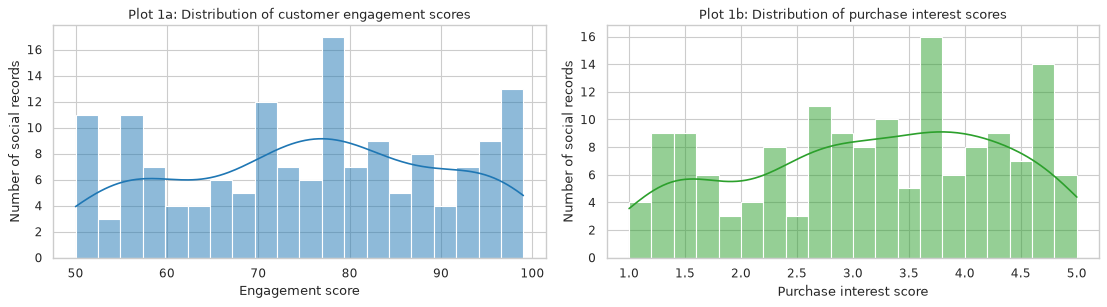

Skewness: engagement -0.105 | purchase interest -0.231


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(social_raw["engagement_score"], kde=True, color="tab:blue", bins=20, ax=axes[0])
axes[0].set_title("Plot 1a: Distribution of customer engagement scores")
axes[0].set_xlabel("Engagement score")
axes[0].set_ylabel("Number of social records")
sns.histplot(social_raw["purchase_interest_score"], kde=True, color="tab:green", bins=20, ax=axes[1])
axes[1].set_title("Plot 1b: Distribution of purchase interest scores")
axes[1].set_xlabel("Purchase interest score")
axes[1].set_ylabel("Number of social records")
plt.tight_layout()
plt.show()

print("Skewness: engagement", round(social_raw["engagement_score"].skew(), 3),
      "| purchase interest", round(social_raw["purchase_interest_score"].skew(), 3))

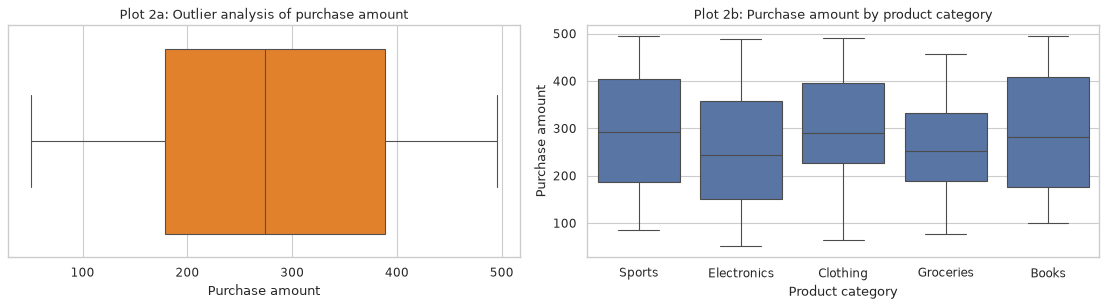

IQR outlier bounds: -135.2 to 702.8 | outliers found: 0 | skewness: 0.059


In [6]:
amount = transactions_raw["purchase_amount"]
q1, q3 = amount.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = transactions_raw[(amount < lower) | (amount > upper)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=amount, color="tab:orange", ax=axes[0])
axes[0].set_title("Plot 2a: Outlier analysis of purchase amount")
axes[0].set_xlabel("Purchase amount")
sns.boxplot(data=transactions_raw, x="product_category", y="purchase_amount", ax=axes[1])
axes[1].set_title("Plot 2b: Purchase amount by product category")
axes[1].set_xlabel("Product category")
axes[1].set_ylabel("Purchase amount")
plt.tight_layout()
plt.show()

print(f"IQR outlier bounds: {lower:.1f} to {upper:.1f} | outliers found: {len(outliers)} | "
      f"skewness: {amount.skew():.3f}")

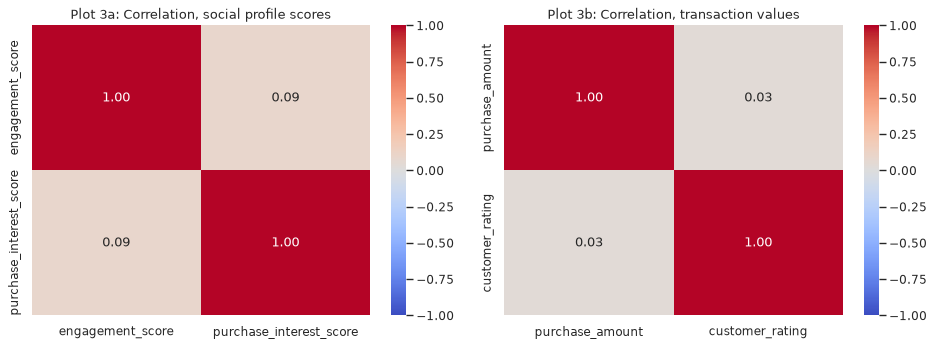

In [7]:
numeric_social = social_raw[["engagement_score", "purchase_interest_score"]]
numeric_transactions = transactions_raw[["purchase_amount", "customer_rating"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(numeric_social.corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Plot 3a: Correlation, social profile scores")
sns.heatmap(numeric_transactions.corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Plot 3b: Correlation, transaction values")
plt.tight_layout()
plt.show()

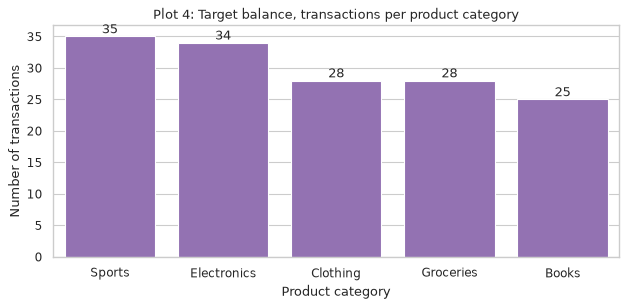

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
order = transactions_raw["product_category"].value_counts().index
sns.countplot(data=transactions_raw, x="product_category", order=order, color="tab:purple", ax=ax)
ax.set_title("Plot 4: Target balance, transactions per product category")
ax.set_xlabel("Product category")
ax.set_ylabel("Number of transactions")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

### EDA interpretation
- **Plot 1 (distributions):** engagement scores spread evenly between 50 and 99 (mean 75.6, skewness -0.11) and purchase
  interest between 1.0 and 5.0 (mean 3.15, skewness -0.23). Neither is strongly skewed, so no log transform is needed.
- **Plot 2 (outliers):** purchase amounts range from 51 to 495 with a median of 274. The IQR rule finds **no outliers**
  (bounds -135 to 703) and the distribution is close to symmetric (skewness 0.06), so no rows are removed or capped.
  Amounts are similar across categories, which is one more sign that the amount says little about *which* product is
  bought.
- **Plot 3 (correlations):** engagement and purchase interest are almost uncorrelated (r = 0.09), so they carry
  different information and both are kept. Purchase amount and rating are also nearly independent.
- **Plot 4 (target balance):** the five categories are fairly balanced (25 to 35 transactions each), so accuracy is a
  meaningful metric and no resampling is required. The smallest class (Books, 25) is still 71% of the largest
  (Sports, 35).

## 5. Data cleaning and ID standardisation

1. Remove the 5 exact duplicate social records.
2. Harmonise IDs: `A178` in the social table and `178` in the transaction table are the same customer, so the numeric part
   becomes a shared integer `customer_id`. Both tables then cover the same range (100 to 199).
3. Convert `purchase_date` to a real date.
4. Fill the 10 missing `customer_rating` values with the median rating and keep a `customer_rating_missing` flag, so
   nothing is hidden. Rating is a post-purchase value and is not a model input, so this choice cannot leak into the
   recommendation model.

In [9]:
social_clean = social_raw.drop_duplicates().copy()
social_clean["customer_id"] = social_clean["customer_id_new"].str.extract(r"(\d+)", expand=False).astype(int)

transactions_clean = transactions_raw.copy()
transactions_clean["customer_id"] = transactions_clean["customer_id_legacy"].astype(int)
transactions_clean["purchase_date"] = pd.to_datetime(transactions_clean["purchase_date"])

median_rating = transactions_clean["customer_rating"].median()
transactions_clean["customer_rating_missing"] = transactions_clean["customer_rating"].isna().astype(int)
transactions_clean["customer_rating"] = transactions_clean["customer_rating"].fillna(median_rating)

print("Social rows after removing duplicates:", len(social_clean), f"(removed {len(social_raw) - len(social_clean)})")
print("Social customer_id range:", social_clean["customer_id"].min(), "to", social_clean["customer_id"].max())
print("Transaction customer_id range:", transactions_clean["customer_id"].min(), "to", transactions_clean["customer_id"].max())
print(f"Missing ratings filled with the median ({median_rating}):", transactions_clean["customer_rating_missing"].sum())

Social rows after removing duplicates: 150 (removed 5)
Social customer_id range: 100 to 199
Transaction customer_id range: 100 to 199
Missing ratings filled with the median (3.0): 10


## 6. Customer-level aggregation and social feature engineering

Each customer's social records become one row of engineered features:

| Feature | Meaning |
|---|---|
| `social_record_count` | how many social records the customer has |
| `avg_engagement_score`, `max_engagement_score` | typical and peak engagement |
| `avg_purchase_interest_score`, `std_purchase_interest_score` | typical purchase interest and how consistent it is (0 for one record) |
| `dominant_platform` | most frequent platform (ties broken alphabetically) |
| `platform_count` | number of different platforms used |
| `positive/neutral/negative_sentiment_share` | share of the customer's reviews with each sentiment |

In [10]:
sentiment_shares = (
    pd.crosstab(social_clean["customer_id"], social_clean["review_sentiment"], normalize="index")
    .rename(columns=lambda s: f"{s.lower()}_sentiment_share")
)

social_agg = social_clean.groupby("customer_id").agg(
    social_record_count=("engagement_score", "size"),
    avg_engagement_score=("engagement_score", "mean"),
    max_engagement_score=("engagement_score", "max"),
    avg_purchase_interest_score=("purchase_interest_score", "mean"),
    std_purchase_interest_score=("purchase_interest_score", "std"),
    dominant_platform=("social_media_platform", lambda x: x.mode().iloc[0]),
    platform_count=("social_media_platform", "nunique"),
).join(sentiment_shares).reset_index()

# A single record has no spread, so its standard deviation is 0 rather than undefined.
social_agg["std_purchase_interest_score"] = social_agg["std_purchase_interest_score"].fillna(0.0)

print("Aggregated social profiles:", social_agg.shape, "| one row per customer:", social_agg["customer_id"].is_unique)
print("Records per customer:", social_agg["social_record_count"].value_counts().sort_index().to_dict())
display(social_agg.head())

Aggregated social profiles: (84, 11) | one row per customer: True
Records per customer: {1: 43, 2: 23, 3: 13, 4: 4, 6: 1}


,customer_id,social_record_count,avg_engagement_score,max_engagement_score,avg_purchase_interest_score,std_purchase_interest_score,dominant_platform,platform_count,negative_sentiment_share,neutral_sentiment_share,positive_sentiment_share
0,100,2,77.000000,81,4.400000,0.000000,Instagram,2,0.500000,0.500000,0.000000
1,101,1,68.000000,68,1.000000,0.000000,Twitter,1,0.000000,1.000000,0.000000
2,102,1,51.000000,51,4.800000,0.000000,LinkedIn,1,0.000000,1.000000,0.000000
3,103,3,64.333333,77,2.866667,0.665833,Instagram,2,0.333333,0.000000,0.666667
4,104,3,83.000000,91,2.933333,1.527525,Twitter,2,0.666667,0.333333,0.000000


**Interpretation:** the 150 unique social records collapse into 84 customers. Most customers (43) have a single record,
while one has 6, so `social_record_count` and `platform_count` capture how active a customer is across platforms.
Averaging the scores gives each customer one stable value, and the sentiment shares keep the full mix of review
opinions instead of only the most common one.

## 7. Merging the datasets and validation

A left many-to-one join attaches each customer's social features to every one of their transactions.

In [11]:
merged_df = pd.merge(
    transactions_clean.drop(columns="customer_id_legacy"),
    social_agg,
    on="customer_id",
    how="left",
    validate="many_to_one",
    indicator=True,
)

matched = merged_df["_merge"] == "both"
print("Merged dataset shape:", merged_df.shape)
print("Transactions before and after merge:", len(transactions_clean), "->", len(merged_df))
print("transaction_id still unique:", merged_df["transaction_id"].is_unique)
print("Transactions with a social profile:", matched.sum())
print("Transactions without a social profile:", (~matched).sum(),
      "from", merged_df.loc[~matched, "customer_id"].nunique(), "customers")
print("Customers with a profile but no transactions:",
      len(set(social_agg["customer_id"]) - set(transactions_clean["customer_id"])))

Merged dataset shape: (150, 18)
Transactions before and after merge: 150 -> 150
transaction_id still unique: True
Transactions with a social profile: 117
Transactions without a social profile: 33 from 14 customers
Customers with a profile but no transactions: 23


**Merge validation:** the merged table has exactly 150 rows, the same as the transaction table, and `transaction_id`
is still unique, so the many-to-one join did not duplicate any purchase. 117 transactions (61 customers) found a social
profile. **33 transactions from 14 customers have no social profile**; they are real purchases with a valid target, so
they are kept rather than dropped (dropping them would lose 22% of the data). 23 customers have a social profile but no
transactions; they have nothing to predict and are correctly left out by the left join.

## 8. Handling unmatched records

For the 33 transactions without a social profile:
- `has_social_profile` is set to 0 (1 otherwise), so a model can learn that these customers are different.
- Engagement and interest scores are filled with the **median of the customers who do have a profile**. The median is
  robust and does not invent extreme values.
- The three sentiment shares are filled with the **average** shares of those customers, because three separate medians
  would no longer add up to 1.
- `social_record_count` and `platform_count` are set to 0, which is literally true: no records, no platforms.
- `dominant_platform` becomes `"None"`.

In [12]:
merged_df["has_social_profile"] = matched.astype(int)
merged_df = merged_df.drop(columns="_merge")

for col in ["social_record_count", "platform_count"]:
    merged_df[col] = merged_df[col].fillna(0).astype(int)
profiled = merged_df[merged_df["has_social_profile"] == 1]
score_cols = ["avg_engagement_score", "max_engagement_score",
              "avg_purchase_interest_score", "std_purchase_interest_score"]
share_cols = ["positive_sentiment_share", "neutral_sentiment_share", "negative_sentiment_share"]
# Medians for the scores; means for the shares, because three separate medians would not add up to 1.
fill_values = pd.concat([profiled[score_cols].median(), profiled[share_cols].mean()])
merged_df[score_cols + share_cols] = merged_df[score_cols + share_cols].fillna(fill_values)
merged_df["dominant_platform"] = merged_df["dominant_platform"].fillna("None")

display(fill_values.round(3).to_frame("value used for customers without a profile"))
print("Missing values left:", int(merged_df.isna().sum().sum()))

,value used for customers without a profile
avg_engagement_score,77.000
max_engagement_score,82.000
avg_purchase_interest_score,3.133
std_purchase_interest_score,0.071
positive_sentiment_share,0.405
neutral_sentiment_share,0.293
negative_sentiment_share,0.301


Missing values left: 0


## 9. Transaction-level feature engineering

Purchases happen once a day from January to May 2024, so the year and day of the month carry no information. The month
and the day of the week can reflect seasonal or weekly buying habits and are added. An engagement-times-interest score
combines how active a customer is with how interested they are in buying.

In [13]:
merged_df["purchase_month"] = merged_df["purchase_date"].dt.month
merged_df["purchase_dayofweek"] = merged_df["purchase_date"].dt.day_of_week
merged_df["engagement_x_interest"] = merged_df["avg_engagement_score"] * merged_df["avg_purchase_interest_score"]

TARGET = "product_category"
ID_COLUMNS = ["transaction_id", "customer_id", "purchase_date"]
POST_PURCHASE = ["purchase_amount", "customer_rating", "customer_rating_missing"]
MODEL_FEATURES = [
    "has_social_profile", "social_record_count", "platform_count",
    "avg_engagement_score", "max_engagement_score",
    "avg_purchase_interest_score", "std_purchase_interest_score", "engagement_x_interest",
    "positive_sentiment_share", "neutral_sentiment_share", "negative_sentiment_share",
    "dominant_platform", "purchase_month", "purchase_dayofweek",
]

merged_df = merged_df[ID_COLUMNS + [TARGET] + POST_PURCHASE + MODEL_FEATURES]
print("Model features:", len(MODEL_FEATURES), "| categorical:", ["dominant_platform"])
display(merged_df.head())

Model features: 14 | categorical: ['dominant_platform']


,transaction_id,customer_id,purchase_date,product_category,purchase_amount,customer_rating,customer_rating_missing,has_social_profile,social_record_count,platform_count,avg_engagement_score,max_engagement_score,avg_purchase_interest_score,std_purchase_interest_score,engagement_x_interest,positive_sentiment_share,neutral_sentiment_share,negative_sentiment_share,dominant_platform,purchase_month,purchase_dayofweek
0,1001,151,2024-01-01,Sports,408,2.3,0,1,3,2,71.666667,82.0,2.166667,1.250333,155.277778,0.000000,0.666667,0.333333,Twitter,1,0
1,1002,192,2024-01-02,Electronics,332,4.2,0,1,1,1,60.000000,60.0,4.300000,0.000000,258.000000,1.000000,0.000000,0.000000,Instagram,1,1
2,1003,114,2024-01-03,Electronics,442,2.1,0,1,1,1,87.000000,87.0,4.800000,0.000000,417.600000,0.000000,0.000000,1.000000,Facebook,1,2
3,1004,171,2024-01-04,Clothing,256,2.8,0,0,0,0,77.000000,82.0,3.133333,0.070711,241.266667,0.405271,0.293447,0.301282,None,1,3
4,1005,160,2024-01-05,Clothing,64,1.3,0,1,3,3,72.666667,89.0,2.500000,0.458258,181.666667,0.333333,0.666667,0.000000,Instagram,1,4


## 10. Final validation and export

In [14]:
checks = {
    "150 rows, one per transaction": len(merged_df) == len(transactions_raw),
    "transaction_id unique": merged_df["transaction_id"].is_unique,
    "no missing values": not merged_df.isna().any().any(),
    "target present in every row": merged_df[TARGET].notna().all(),
    "shares sum to 1 per row": np.allclose(
        merged_df[["positive_sentiment_share", "neutral_sentiment_share", "negative_sentiment_share"]].sum(axis=1), 1),
    "post-purchase columns excluded from features": not set(POST_PURCHASE) & set(MODEL_FEATURES),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values()), "A validation check failed"

merged_df.to_csv(OUTPUT_CSV, index=False, date_format="%Y-%m-%d")
print(f"Saved {OUTPUT_CSV.relative_to(REPO_ROOT)}: {merged_df.shape[0]} rows x {merged_df.shape[1]} columns")

,passed
"150 rows, one per transaction",True
transaction_id unique,True
no missing values,True
target present in every row,True
shares sum to 1 per row,True
post-purchase columns excluded from features,True


Saved datasets/merged_customer_recommendation_dataset.csv: 150 rows x 21 columns


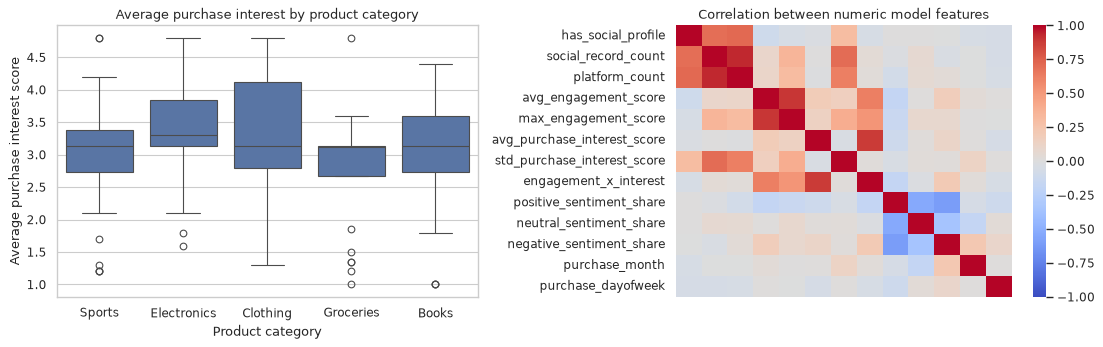

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=merged_df, x=TARGET, y="avg_purchase_interest_score", ax=axes[0])
axes[0].set_title("Average purchase interest by product category")
axes[0].set_xlabel("Product category")
axes[0].set_ylabel("Average purchase interest score")
numeric_features = merged_df[MODEL_FEATURES].select_dtypes("number")
sns.heatmap(numeric_features.corr(), cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1],
            xticklabels=False, yticklabels=True)
axes[1].set_title("Correlation between numeric model features")
plt.tight_layout()
plt.show()

**Interpretation:** the medians of average purchase interest are close across categories (3.12 to 3.13), with
Electronics slightly higher (3.30). Many values sit exactly at 3.13 because that is the median used for customers
without a profile. No single feature separates the categories on its own, so the recommendation model must combine
several features, and modest accuracy should be expected from this small dataset.

The heatmap shows which engineered features overlap: `social_record_count` and `platform_count` (r = 0.94),
average and maximum engagement (r = 0.89), and purchase interest and `engagement_x_interest` (r = 0.88) are strongly
related. The sentiment shares are negatively related to each other (r = -0.60 and -0.53) because they add up to 1.
Tree models such as Random Forest handle these overlaps well; for Logistic Regression, regularisation (the default
in scikit-learn) keeps them from destabilising the coefficients.

### Summary
- **Output:** `datasets/merged_customer_recommendation_dataset.csv`, 150 rows (one per transaction), no missing values,
  validated with the checks above.
- **Cleaning:** 5 duplicate social records removed, IDs harmonised to one integer `customer_id`, dates converted,
  10 missing ratings filled with the median and flagged.
- **Merge:** left many-to-one join keeps all 150 transactions with no duplication; 33 transactions from 14 customers
  without a social profile are kept, flagged with `has_social_profile = 0` and filled with profile medians and average shares.
- **Feature engineering:** 14 model features from both sources (activity counts, engagement and interest statistics,
  sentiment shares, dominant platform, purchase month and weekday, and an engagement-times-interest score).
- **For the product recommendation model:** target `product_category` (5 balanced classes); inputs `MODEL_FEATURES`
  with `dominant_platform` one-hot encoded. `purchase_amount` and `customer_rating` are kept for analysis only.